# Emotionen in englischen Tweets: Baseline und TF-IDF mit logistischer Regression

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/projektarbeit_emotion.ipynb)

## 1 Fragestellung

Welche von sechs Emotionen (sadness, joy, love, anger, fear, surprise) ist in einem englischen Tweet ausgedrückt, und um wie viel liegen TF-IDF-Merkmale mit logistischer Regression über einer Baseline, bei der jeder Tweet als häufigste Klasse gilt?

**Anwendungsfall.** Ein Kundendienst sortiert eingehende Kurznachrichten nach der ausgedrückten Emotion, sodass Nachrichten mit anger oder fear zuerst gelesen werden.

**Metrik.** Hauptmetrik ist der Makro-F1 auf den Testdaten: jede der sechs Klassen hat dasselbe Gewicht, auch surprise mit 66 Testtexten. Daneben steht die Accuracy. Bei der Baseline gilt jeder der 2'000 Testtexte als joy; richtig sind 695, die Accuracy beträgt 0.347 und der Makro-F1 0.086.

In [1]:
import io
import re
import urllib.request
from collections import Counter
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline

SEED = 42  # für die Stichprobe von Texten
DATA_URL = "https://huggingface.co/datasets/dair-ai/emotion/resolve/cab853a1dbdf4c42c2b3ef2173804746df8825fe/split/{part}-00000-of-00001.parquet"
CLASSES = ["sadness", "joy", "love", "anger", "fear", "surprise"]  # Label 0 bis 5 in der Reihenfolge der Dataset Card
K = len(CLASSES)

pd.set_option("display.float_format", "{:.3f}".format)  # drei Stellen, auch in Tabellen
pd.set_option("display.max_colwidth", 200)


def tausender(n):
    return f"{int(n):,}".replace(",", "'")


def prozent(x):
    return f"{100 * x:.1f} %"

## 2 Daten

**Quelle.** dair-ai/emotion auf Hugging Face, Konfiguration `split`, Parquet-Dateien `train`, `validation` und `test`; Beschreibung in der [Dataset Card](https://huggingface.co/datasets/dair-ai/emotion). Zitierweise laut Dataset Card: Saravia, Liu, Huang, Wu und Chen (2018), *CARER: Contextualized Affect Representations for Emotion Recognition*, Proceedings of the 2018 Conference on Empirical Methods in Natural Language Processing (EMNLP), Brüssel, S. 3687-3697, [doi:10.18653/v1/D18-1404](https://doi.org/10.18653/v1/D18-1404), [ACL Anthology D18-1404](https://aclanthology.org/D18-1404/).

**Lizenz.** In der Dataset Card steht im Metadatenfeld `license` der Wert `other`; unter «Licensing Information» lautet der Satz: «The dataset should be used for educational and research purposes only.»

**Sprache.** Englisch. Jede Zeile hat einen Text (`text`) und ein Label von 0 bis 5 (`label`). Die Reihenfolge der Dataset Card: 0 sadness, 1 joy, 2 love, 3 anger, 4 fear, 5 surprise.

**Umfang.** 16'000 Trainings-, 2'000 Validierungs- und 2'000 Testtexte.

In [2]:
def load_emotion():
    """Lädt die drei Parquet-Dateien der Konfiguration split und gibt drei Tabellen mit den Spalten text und label zurück."""
    tables = {}
    for part in ["train", "validation", "test"]:
        url = DATA_URL.format(part=part)
        try:
            with urllib.request.urlopen(url, timeout=120) as response:
                tables[part] = pd.read_parquet(io.BytesIO(response.read()))
        except OSError as error:
            raise SystemExit(f"Download fehlgeschlagen: {url}\n{error}")
    return tables


tables = load_emotion()
train, validation, test = tables["train"], tables["validation"], tables["test"]
for part, table in tables.items():
    print(f"{part}: {tausender(len(table))} Texte, Spalten {list(table.columns)}")
print(f"Wörter im Training: {tausender(train.text.str.split().str.len().sum())}")
train.head(3).assign(klasse=lambda t: [CLASSES[k] for k in t.label])

train: 16'000 Texte, Spalten ['text', 'label']
validation: 2'000 Texte, Spalten ['text', 'label']
test: 2'000 Texte, Spalten ['text', 'label']
Wörter im Training: 306'661


,text,label,klasse
0,i didnt feel humiliated,0,sadness
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,0,sadness
2,im grabbing a minute to post i feel greedy wrong,3,anger


In [3]:
overview = pd.DataFrame(index=CLASSES)
for part, table in tables.items():
    counts = table.label.value_counts().sort_index()
    overview[part] = counts.values
    overview[part + " Anteil"] = [prozent(c / len(table)) for c in counts]
overview

,train,train Anteil,validation,validation Anteil,test,test Anteil
sadness,4666,29.2 %,550,27.5 %,581,29.0 %
joy,5362,33.5 %,704,35.2 %,695,34.8 %
love,1304,8.2 %,178,8.9 %,159,8.0 %
anger,2159,13.5 %,275,13.8 %,275,13.8 %
fear,1937,12.1 %,212,10.6 %,224,11.2 %
surprise,572,3.6 %,81,4.0 %,66,3.3 %


### Bereinigung

Die Texte sind kleingeschrieben und ohne Satzzeichen. Die Aufteilung ist veröffentlicht und bleibt unverändert, damit die Zahlen mit denen anderer Arbeiten auf diesem Datensatz vergleichbar sind. Gezählt werden Grossbuchstaben, Satzzeichen, doppelte Texte, Texte mit zwei Labels und Texte, die im Training und im Test stehen.

In [4]:
upper = int(train.text.str.contains(r"[A-Z]").sum())
punct = int(train.text.str.contains(r"[.,;:!?]").sum())
print(f"Training: {upper} Texte mit Grossbuchstaben, {punct} mit Satzzeichen")
print(f"doppelte Texte im Training: {train.text.duplicated().sum()}")
labels_per_text = train.groupby("text").label.nunique()
print(f"Trainingstexte mit zwei verschiedenen Labels: {(labels_per_text > 1).sum()}")
overlap = test.text.isin(set(train.text))
print(f"Testtexte, die auch im Training stehen: {overlap.sum()} von {tausender(len(test))}")

Training: 0 Texte mit Grossbuchstaben, 0 mit Satzzeichen
doppelte Texte im Training: 31
Trainingstexte mit zwei verschiedenen Labels: 30
Testtexte, die auch im Training stehen: 11 von 2'000


Im Training stehen 31 doppelte Texte, 30 Texte haben zwei verschiedene Labels, und 11 der 2'000 Testtexte stehen auch im Training. Alle bleiben im Datensatz.

## 3 Deskriptive Analyse

Zwei Kennzahlen je Klasse: die Länge der Texte in Wörtern und die zehn häufigsten Wörter ohne Stoppwörter.

alle Klassen: Median 17 Wörter, Maximum 66 Wörter
Spanne der Klassenmediane: 3 Wörter
          Median  Mittel  Maximum
sadness     16.0    18.4       66
joy         18.0    19.5       64
love        19.0    20.7       63
anger       17.0    19.2       62
fear        17.0    18.8       60
surprise    18.0    20.0       60


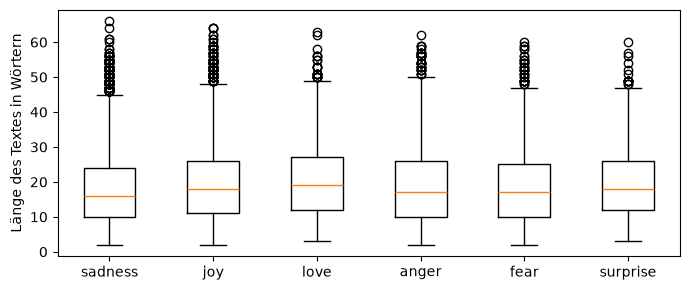

In [5]:
for table in tables.values():
    table["words"] = table.text.str.split().str.len()
length = train.groupby("label").words.agg(Median="median", Mittel="mean", Maximum="max")
length.index = CLASSES
print(f"alle Klassen: Median {train.words.median():.0f} Wörter, Maximum {train.words.max()} Wörter")
print(f"Spanne der Klassenmediane: {length.Median.max() - length.Median.min():g} Wörter")
print(length.to_string(float_format="{:.1f}".format))

fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot([train.words[train.label == k] for k in range(K)])
ax.set_xticks(range(1, K + 1), CLASSES)
ax.set_ylabel("Länge des Textes in Wörtern")
plt.tight_layout()
plt.show()

In [6]:
def words(text):
    """Kleingeschriebene Wörter aus mindestens zwei Zeichen, wie sie der TF-IDF-Vektorisierer sieht."""
    return re.findall(r"\b\w\w+\b", text.lower())


top_words = {}
for k, name in enumerate(CLASSES):
    counter = Counter(w for t in train.text[train.label == k] for w in words(t) if w not in ENGLISH_STOP_WORDS)
    top_words[name] = [w for w, _ in counter.most_common(10)]
    print(f"{name:9s}", top_words[name])

common = sorted(set.intersection(*map(set, top_words.values())))
print("in den Listen aller sechs Klassen:", common)
unique_words = {}
for name, listed in top_words.items():
    others = set().union(*(set(v) for n, v in top_words.items() if n != name))
    unique_words[name] = [w for w in listed if w not in others]
    print(f"nur in der Liste von {name}:", unique_words[name])

sadness   ['feel', 'feeling', 'like', 'im', 'just', 'really', 'know', 'ive', 'time', 'little']


joy       ['feel', 'feeling', 'like', 'im', 'just', 'really', 'time', 'know', 'make', 'want']
love      ['feel', 'feeling', 'like', 'im', 'love', 'just', 'really', 'know', 'sweet', 'loving']
anger     ['feel', 'feeling', 'like', 'im', 'just', 'really', 'time', 'know', 'little', 'people']
fear      ['feel', 'feeling', 'im', 'like', 'just', 'little', 'bit', 'know', 'really', 'people']
surprise  ['feel', 'feeling', 'im', 'like', 'amazed', 'impressed', 'overwhelmed', 'weird', 'just', 'surprised']
in den Listen aller sechs Klassen: ['feel', 'feeling', 'im', 'just', 'like']
nur in der Liste von sadness: ['ive']
nur in der Liste von joy: ['make', 'want']
nur in der Liste von love: ['love', 'sweet', 'loving']
nur in der Liste von anger: []
nur in der Liste von fear: ['bit']
nur in der Liste von surprise: ['amazed', 'impressed', 'overwhelmed', 'weird', 'surprised']


In [7]:
feel = train.text.str.contains(r"\b(?:feel|feels|feeling|feelings|felt)\b")
print(f"Trainingstexte mit einer Form von feel: {tausender(feel.sum())} von {tausender(len(train))} ({prozent(feel.mean())})")

Trainingstexte mit einer Form von feel: 15'798 von 16'000 (98.7 %)


Die Texte sind kurz: der Median liegt bei 17 Wörtern, der längste Text hat 66. Die Mediane der Klassen liegen zwischen 16 (sadness) und 19 (love), also im Abstand von 3 Wörtern.

In den Listen der häufigsten Wörter stehen fünf Wörter in allen sechs Klassen (*feel*, *feeling*, *im*, *just*, *like*). Eigene Wörter haben vor allem love (*love*, *sweet*, *loving*) und surprise (*amazed*, *impressed*, *overwhelmed*, *weird*, *surprised*). 98.7 % der Trainingstexte (15'798 von 16'000) haben eine Form von *feel*: es sind Selbstbeschreibungen der Art «i feel …».

## 4 Trainings- und Testdaten

Die Aufteilung ist die der Dataset Card: 16'000 Trainingstexte und 2'000 Testtexte. Die Klassenanteile der beiden Teile liegen nahe beieinander (surprise: 3.6 % im Training, 3.3 % im Test). Die Testdaten bleiben bis zur Evaluation unberührt.

**Validierungsdaten.** Die 2'000 Validierungstexte bleiben ungenutzt, weil keine Einstellung gewählt wird: für TF-IDF und logistische Regression gelten die Voreinstellungen von scikit-learn. Eine Wahl wie die von `C` oder der Anzahl der Epochen bei der Feinabstimmung geschieht auf den Validierungsdaten; die Schlusszahl wird einmal auf den Testdaten gemessen.

In [8]:
X_train, y_train = train.text, train.label
X_test, y_test = test.text, test.label
print(f"Training: {tausender(len(X_train))} Texte   Validierung: {tausender(len(validation))} Texte (ungenutzt)   Test: {tausender(len(X_test))} Texte")

Training: 16'000 Texte   Validierung: 2'000 Texte (ungenutzt)   Test: 2'000 Texte


## 5 Methoden

**Baseline.** Die häufigste Klasse im Training: jeder Text gilt als joy. Sie hat 5'362 der 16'000 Trainingstexte (33.5 %).

**Methode aus dem Kurs.** TF-IDF-Merkmale (Kapitel 4, Word Representations) und eine logistische Regression, die Textklassifikation der Modulbeschreibung, mit den Voreinstellungen von scikit-learn (`C=1.0`, Solver `lbfgs`, höchstens 1'000 Iterationen). Bei sechs Klassen hat die logistische Regression sechs Gewichtsvektoren und eine Softmax über sechs Werte, wie die Schicht bei der Feinabstimmung.

Begründung der Wahl: TF-IDF mit logistischer Regression ist aus dem Kurs bekannt, das Training ist ohne GPU möglich, und für jedes der 15'186 Wörter des Wortschatzes gibt es je Klasse ein Gewicht, das sich lesen lässt. Die Labels bleiben ganze Zahlen von 0 bis 5; so liegen sie auch bei der Feinabstimmung vor.

In [9]:
models = {
    "Baseline (häufigste Klasse)": DummyClassifier(strategy="most_frequent"),
    "TF-IDF + logistische Regression": make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000, random_state=SEED)),
}
for model in models.values():
    model.fit(X_train, y_train)

baseline = models["Baseline (häufigste Klasse)"]
classifier = models["TF-IDF + logistische Regression"]
vectorizer, regression = classifier[0], classifier[-1]
assert list(regression.classes_) == list(range(K))  # Spalten von predict_proba in der Reihenfolge von CLASSES
majority = int(baseline.predict(X_test)[0])
n_majority = int((y_train == majority).sum())
print(f"Baseline: jeder Text gilt als {CLASSES[majority]} ({tausender(n_majority)} von {tausender(len(y_train))} Trainingstexten, {prozent(n_majority / len(y_train))})")
print(f"Wortschatz V = {tausender(len(vectorizer.vocabulary_))}   Gewichtsmatrix W der Regression: {regression.coef_.shape[0]} x {tausender(regression.coef_.shape[1])}")

Baseline: jeder Text gilt als joy (5'362 von 16'000 Trainingstexten, 33.5 %)
Wortschatz V = 15'186   Gewichtsmatrix W der Regression: 6 x 15'186


## 6 Evaluation

Precision, Recall und F1 je Klasse, gemessen auf den 2'000 Testtexten. Der F1 einer Klasse ist das harmonische Mittel von Precision und Recall dieser Klasse.

In [10]:
predicted = classifier.predict(X_test)
precision, recall, f1, support = precision_recall_fscore_support(y_test, predicted, labels=list(range(K)), zero_division=0)
report = pd.DataFrame({"Precision": precision, "Recall": recall, "F1": f1, "Anzahl Test": support}, index=CLASSES)
macro = pd.DataFrame([[precision.mean(), recall.mean(), f1.mean(), support.sum()]], index=["Makro-Mittel"], columns=report.columns)
report = pd.concat([report, macro])
report

,Precision,Recall,F1,Anzahl Test
sadness,0.889,0.928,0.908,581
joy,0.832,0.955,0.889,695
love,0.823,0.585,0.684,159
anger,0.902,0.807,0.852,275
fear,0.870,0.777,0.821,224
surprise,0.838,0.470,0.602,66
Makro-Mittel,0.859,0.754,0.793,2000


Der Makro-F1 ist das Mittel der K = 6 F1-Werte mit gleichem Gewicht:

$\text{Makro-F1} = \frac{1}{K}\sum_{k=1}^{K} F1_k$

In der Accuracy hat jeder Text das Gewicht 1; der Wert hängt darum vor allem von den grossen Klassen ab. Im Makro-F1 hat jede Klasse das Gewicht 1/K: surprise mit 66 Testtexten hat dasselbe Gewicht wie joy mit 695. Bei ungleichen Klassen liegen die beiden Zahlen auseinander: hier um 0.069 (Accuracy 0.862, Makro-F1 0.793), und der niedrigste F1 gehört der kleinsten Klasse: surprise mit 0.602.

In [11]:
def scores(model):
    predicted = model.predict(X_test)
    return {"Accuracy": accuracy_score(y_test, predicted),
            "Makro-F1": f1_score(y_test, predicted, labels=list(range(K)), average="macro", zero_division=0)}


summary = pd.DataFrame({name: scores(model) for name, model in models.items()}).T
summary.loc["Abstand zur Baseline"] = summary.iloc[1] - summary.iloc[0]
correct = {name: int((model.predict(X_test) == y_test).sum()) for name, model in models.items()}
print(f"richtig zugeordnet von {tausender(len(y_test))} Testtexten: " + ", ".join(f"{n} {tausender(c)}" for n, c in correct.items()))
distance = summary.loc["Abstand zur Baseline"]
print(f"Abstand zur Baseline: Accuracy {distance['Accuracy']:+.3f}, Makro-F1 {distance['Makro-F1']:+.3f}")
shown = [float(f"{v:.3f}") for v in summary["Accuracy"].iloc[:2]]
print(f"Differenz der gerundeten Accuracy-Werte {shown[1]:.3f} und {shown[0]:.3f}: {shown[1] - shown[0]:.3f}")
print(f"Accuracy minus Makro-F1 der logistischen Regression: {summary.iloc[1, 0] - summary.iloc[1, 1]:.3f}")
summary

richtig zugeordnet von 2'000 Testtexten: Baseline (häufigste Klasse) 695, TF-IDF + logistische Regression 1'723
Abstand zur Baseline: Accuracy +0.514, Makro-F1 +0.707
Differenz der gerundeten Accuracy-Werte 0.862 und 0.347: 0.515
Accuracy minus Makro-F1 der logistischen Regression: 0.069


,Accuracy,Makro-F1
Baseline (häufigste Klasse),0.347,0.086
TF-IDF + logistische Regression,0.862,0.793
Abstand zur Baseline,0.514,0.707


Der Abstand zur Baseline beträgt +0.514 in der Accuracy (1'723 gegen 695 richtige Texte von 2'000) und +0.707 im Makro-F1. Beide Abstände werden aus den ungerundeten Werten gebildet; aus den angezeigten Werten 0.862 und 0.347 ergäbe sich 0.515.

In [12]:
matrix = confusion_matrix(y_test, predicted, labels=list(range(K)))
pd.DataFrame(matrix, index=[f"wahr: {c}" for c in CLASSES], columns=[f"vorhergesagt: {c}" for c in CLASSES])

,vorhergesagt: sadness,vorhergesagt: joy,vorhergesagt: love,vorhergesagt: anger,vorhergesagt: fear,vorhergesagt: surprise
wahr: sadness,539,25,1,12,4,0
wahr: joy,8,664,17,2,2,2
wahr: love,9,55,93,2,0,0
wahr: anger,23,23,1,222,6,0
wahr: fear,21,16,1,8,174,4
wahr: surprise,6,15,0,0,14,31


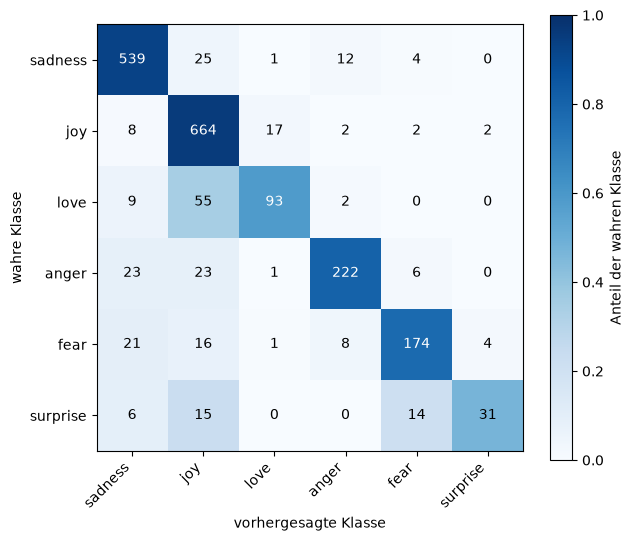

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
image = ax.imshow(matrix / matrix.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K), CLASSES, rotation=45, ha="right")
ax.set_yticks(range(K), CLASSES)
ax.set_xlabel("vorhergesagte Klasse")
ax.set_ylabel("wahre Klasse")
for a in range(K):
    for b in range(K):
        ax.text(b, a, matrix[a, b], ha="center", va="center", color="white" if matrix[a, b] > 0.5 * matrix[a].sum() else "black")
fig.colorbar(image, label="Anteil der wahren Klasse")
plt.tight_layout()
plt.show()

In [14]:
off_diagonal = matrix - np.diag(np.diag(matrix))
pair_counts = {(a, b): int(off_diagonal[a, b] + off_diagonal[b, a]) for a in range(K) for b in range(a + 1, K)}
a, b = max(pair_counts, key=pair_counts.get)
print(f"am häufigsten verwechseltes Paar: {CLASSES[a]} und {CLASSES[b]}, {pair_counts[(a, b)]} Testtexte")
print(f"  wahr {CLASSES[a]}, vorhergesagt {CLASSES[b]}: {matrix[a, b]} von {matrix[a].sum()}")
print(f"  wahr {CLASSES[b]}, vorhergesagt {CLASSES[a]}: {matrix[b, a]} von {matrix[b].sum()}")
c, d = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
print(f"häufigster einzelner Fehler: wahr {CLASSES[c]}, vorhergesagt {CLASSES[d]}: {matrix[c, d]} von {matrix[c].sum()}")
fresh = ~overlap.values
print(f"Accuracy auf den {tausender(fresh.sum())} Testtexten ohne Überschneidung mit dem Training: {accuracy_score(y_test[fresh], predicted[fresh]):.3f}")

am häufigsten verwechseltes Paar: joy und love, 72 Testtexte
  wahr joy, vorhergesagt love: 17 von 695
  wahr love, vorhergesagt joy: 55 von 159
häufigster einzelner Fehler: wahr love, vorhergesagt joy: 55 von 159
Accuracy auf den 1'989 Testtexten ohne Überschneidung mit dem Training: 0.865


Das am häufigsten verwechselte Paar ist das ungeordnete Paar mit der grössten Summe beider Fehlerzellen: joy und love mit 72 Testtexten. Davon sind 17 Texte der Klasse joy als love vorhergesagt und 55 Texte der Klasse love als joy. Der häufigste einzelne Fehler ist love als joy mit 55 von 159 Texten dieser Klasse.

## 7 Fehleranalyse

Bei 277 von 2'000 Testtexten weicht die vorhergesagte Klasse von der wahren ab. Gewählt sind die drei Fehler, bei denen die vorhergesagte Klasse die grösste Wahrscheinlichkeit hat; bei gleicher Wahrscheinlichkeit gilt die Reihenfolge im Testdatensatz.

In [15]:
probabilities = classifier.predict_proba(X_test)
predicted_class = probabilities.argmax(axis=1)
errors = pd.DataFrame({
    "text": X_test.values,
    "wahr": [CLASSES[k] for k in y_test],
    "vorhergesagt": [CLASSES[k] for k in predicted_class],
    "P(vorhergesagt)": probabilities.max(axis=1),
    "P(wahr)": probabilities[np.arange(len(y_test)), y_test.values],
})
errors = errors[errors.wahr != errors.vorhergesagt].sort_values("P(vorhergesagt)", ascending=False, kind="stable")
print(f"Testtexte mit abweichender Vorhersage: {len(errors)} von {tausender(len(X_test))}")

vocabulary = vectorizer.get_feature_names_out()


def contributions(text, k, n=2):
    """Die n Wörter des Textes mit dem grössten Beitrag zum Wert z_k: TF-IDF-Wert mal Gewicht der Klasse k."""
    product = vectorizer.transform([text]).multiply(regression.coef_[k]).tocsr()
    order = np.argsort(-product.data)[:n]
    return [(vocabulary[product.indices[i]], float(product.data[i])) for i in order]


for rank, (index, row) in enumerate(errors.head(3).iterrows(), start=1):
    true_k, predicted_k = CLASSES.index(row.wahr), CLASSES.index(row.vorhergesagt)
    print(f"{rank}. Testtext {index}: wahr {row.wahr}, vorhergesagt {row.vorhergesagt}, "
          f"P(vorhergesagt) = {row['P(vorhergesagt)']:.3f}, P(wahr) = {row['P(wahr)']:.3f}")
    print(f"   {row.text}")
    print("   Beiträge zu", row.vorhergesagt + ":", ", ".join(f"{w} {c:.2f}" for w, c in contributions(row.text, predicted_k)))
    print("   Beiträge zu", row.wahr + ":", ", ".join(f"{w} {c:.2f}" for w, c in contributions(row.text, true_k)))

Testtexte mit abweichender Vorhersage: 277 von 2'000
1. Testtext 1943: wahr sadness, vorhergesagt anger, P(vorhergesagt) = 0.836, P(wahr) = 0.092
   i didn t mean to get angry with you bommie i just can t control my feelings hellip i just hated myself why i am like this the dara who can t get over with that b
   Beiträge zu anger: angry 1.04, hated 0.95
   Beiträge zu sadness: hated 0.35, get 0.20
2. Testtext 265: wahr love, vorhergesagt joy, P(vorhergesagt) = 0.825, P(wahr) = 0.108
   i feel so blessed and honored that we get to be its parents
   Beiträge zu joy: honored 1.52, blessed 0.30
   Beiträge zu love: blessed 1.64, we 0.22
3. Testtext 1154: wahr joy, vorhergesagt love, P(vorhergesagt) = 0.802, P(wahr) = 0.181
   i feel that passionate about
   Beiträge zu love: passionate 4.06, about 0.30
   Beiträge zu joy: passionate 0.94, feel 0.32


In [16]:
joy = CLASSES.index("joy")
involved = ((y_test.values == joy) | (predicted_class == joy)) & (y_test.values != predicted_class)
print(f"Fehler, an denen joy beteiligt ist (wahr oder vorhergesagt): {involved.sum()} von {len(errors)}")

weights = pd.DataFrame(regression.coef_.T, index=vocabulary, columns=CLASSES)
top_weights = {name: list(weights[name].nlargest(5).index) for name in CLASSES}
for name, listed in top_weights.items():
    print(f"grösste Gewichte für {name:9s}", listed)

Fehler, an denen joy beteiligt ist (wahr oder vorhergesagt): 165 von 277
grösste Gewichte für sadness   ['lethargic', 'melancholy', 'punished', 'burdened', 'missed']
grösste Gewichte für joy       ['satisfied', 'superior', 'innocent', 'successful', 'pleasant']
grösste Gewichte für love      ['sympathetic', 'caring', 'nostalgic', 'longing', 'naughty']
grösste Gewichte für anger     ['greedy', 'resentful', 'offended', 'dangerous', 'irritable']
grösste Gewichte für fear      ['terrified', 'pressured', 'shaken', 'vulnerable', 'reluctant']
grösste Gewichte für surprise  ['amazed', 'impressed', 'curious', 'surprised', 'shocked']


Der Beitrag eines Wortes zu einer Klasse ist sein TF-IDF-Wert mal sein Gewicht für diese Klasse; die Summe der Beiträge und des Bias ist der Wert z_k der Klasse.

- **Text 1** (wahr sadness, vorhergesagt anger, P = 0.836): *angry* und *hated* haben die Beiträge 1.04 und 0.95 zu anger. Für sadness ist *hated* mit 0.35 der grösste Beitrag.
- **Text 2** (wahr love, vorhergesagt joy, P = 0.825): *honored* hat den Beitrag 1.52 zu joy, *blessed* den Beitrag 1.64 zu love. Der Wert z_joy liegt über z_love (P(love) = 0.108).
- **Text 3** (wahr joy, vorhergesagt love, P = 0.802): *passionate* hat den Beitrag 4.06 zu love und 0.94 zu joy.

In allen drei Texten steht ein Wort mit einem Beitrag über 1 zur vorhergesagten Klasse. Die Texte 2 und 3 liegen auf dem am häufigsten verwechselten Paar joy und love, und die Labels sind aus Hashtags abgeleitet. Von 277 Fehlern betreffen 165 die Klasse joy, wahr oder vorhergesagt. Die drei grössten Gewichte jeder Klasse: sadness: *lethargic*, *melancholy*, *punished*; joy: *satisfied*, *superior*, *innocent*; love: *sympathetic*, *caring*, *nostalgic*; anger: *greedy*, *resentful*, *offended*; fear: *terrified*, *pressured*, *shaken*; surprise: *amazed*, *impressed*, *curious*.

## 8 Prototyp

Die Funktion `classify(text)` hat einen neuen Text als Eingabe und die Klasse mit den sechs Wahrscheinlichkeiten als Rückgabe. In Colab ist `text` ein Eingabefeld. Bei TF-IDF gilt Kleinschreibung automatisch (`lowercase=True`), und Satzzeichen fallen bei der Zerlegung in Wörter weg.

In [17]:
def classify(text):
    """Klasse und die sechs Wahrscheinlichkeiten für einen neuen Text."""
    probabilities = classifier.predict_proba([text])[0]
    probabilities_by_class = {c: round(float(p), 3) for c, p in zip(CLASSES, probabilities)}
    return CLASSES[int(probabilities.argmax())], probabilities_by_class


text = "i feel delighted that my friends came to visit me today"  # @param {type:"string"}
print(classify(text))
print(classify("i am terrified of the exam tomorrow"))

('joy', {'sadness': 0.203, 'joy': 0.559, 'love': 0.07, 'anger': 0.109, 'fear': 0.027, 'surprise': 0.031})
('fear', {'sadness': 0.019, 'joy': 0.024, 'love': 0.012, 'anger': 0.018, 'fear': 0.922, 'surprise': 0.006})


## 9 Feinabstimmung

Bei der Feinabstimmung stammt der Vektor für die Klassifikation aus einem vortrainierten Transformer-Netz (DistilBERT); das Training steht in der Trainer-Zelle des Notebooks zu Kapitel 9.

**TF-IDF mit logistischer Regression.** Ein Text ist ein Vektor $x$ der Länge $V$ = 15'186. Die Regression hat eine Gewichtsmatrix $W$ der Form $K \times V$ = 6 x 15'186 und einen Bias $b$:

$z = W x + b, \qquad p_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$

**Der Vektor von `[CLS]`.** Vor dem Text steht das Token `[CLS]`. Der Ausgabevektor des Netzes an dieser ersten Position ist $h \in \mathbb{R}^{768}$. In der einfachsten Form gilt für eine neue Schicht mit der Matrix $W \in \mathbb{R}^{K \times 768}$ und dem Bias $b \in \mathbb{R}^{K}$:

$z = W h + b, \qquad p = \operatorname{softmax}(z), \qquad K = 6$

Das sind $K \cdot 768 + K$ = 4'614 Gewichte in der Schicht `classifier`. Bei DistilBERT kommen 590'592 Gewichte in `pre_classifier` hinzu (siehe unten), zusammen 595'206 neue Gewichte. Bei der Feinabstimmung werden alle neuen Gewichte und alle vortrainierten Gewichte des Netzes verändert, mit dem Gradienten der Cross-Entropy zwischen $p$ und dem wahren Label.

**Der Kopf in `transformers` 5.15.1.** In `transformers/models/distilbert/modeling_distilbert.py` lautet die Initialisierung von `DistilBertForSequenceClassification`:

```python
self.distilbert = DistilBertModel(config)
self.pre_classifier = nn.Linear(config.dim, config.dim)
self.classifier = nn.Linear(config.dim, config.num_labels)
self.dropout = nn.Dropout(config.seq_classif_dropout)
```

und im Vorwärtsschritt:

```python
hidden_state = distilbert_output[0]  # (bs, seq_len, dim)
pooled_output = hidden_state[:, 0]  # (bs, dim)
pooled_output = self.pre_classifier(pooled_output)  # (bs, dim)
pooled_output = nn.ReLU()(pooled_output)  # (bs, dim)
pooled_output = self.dropout(pooled_output)  # (bs, dim)
logits = self.classifier(pooled_output)  # (bs, num_labels)
```

DistilBERT hat zwei neue Schichten: `pre_classifier` (768 × 768, danach ReLU und Dropout mit p = 0.2) und `classifier` (K × 768). Der Checkpoint `distilbert-base-uncased` hat für beide keine Gewichte; ihre Anfangswerte sind zufällig. Die Gleichung $z = W h + b$ gilt für `classifier`, mit dem Ausgang von ReLU und Dropout hinter `pre_classifier` als $h$. `DistilBertModel` hat keinen Pooler.

`BertForSequenceClassification` hat in derselben Fassung eine neue Schicht:

```python
self.bert = BertModel(config)
classifier_dropout = (
    config.classifier_dropout if config.classifier_dropout is not None else config.hidden_dropout_prob
)
self.dropout = nn.Dropout(classifier_dropout)
self.classifier = nn.Linear(config.hidden_size, config.num_labels)
```

```python
pooled_output = outputs[1]
pooled_output = self.dropout(pooled_output)
logits = self.classifier(pooled_output)
```

`outputs[1]` ist der Ausgang des Poolers `BertPooler` (`dense` 768 × 768 mit tanh, angewendet auf den Vektor des ersten Tokens). Dieser Pooler gehört zum vortrainierten Checkpoint `bert-base-uncased` (Tensor `bert.pooler.dense.weight`); in `BertForPreTraining` ist er die Eingabe der Aufgabe Next Sentence Prediction. Bei BERT ist $h$ in $z = W h + b$ der Ausgang des Poolers, und nur `classifier` hat zufällige Anfangswerte.

**Der Code.** Das Training steht im Notebook `ch09_pre_training_paradigms.ipynb`, Abschnitt «9.2.4 Fine-tuning BERT for Downstream Tasks», in der Zelle mit `Trainer` und `TrainingArguments`: [Notebook auf Colab öffnen](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch09_pre_training_paradigms.ipynb). In der Zelle steht `BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)`; vier Beispieltexte werden in drei Epochen mit der Lernrate 2e-5 und der Batchgrösse 4 trainiert. Für die sechs Emotionen werden vier Stellen geändert: der Checkpoint `distilbert-base-uncased` mit der Klasse `DistilBertForSequenceClassification` und dem Tokenizer `AutoTokenizer.from_pretrained("distilbert-base-uncased")` (die Zelle in ch09 hat `BertTokenizer`), `num_labels=6`, die Daten (16'000 Trainingstexte mit den Labels 0 bis 5; im Beispiel sind es vier Texte mit den Labels 0 und 1) und die Wahl der Epochenzahl auf den 2'000 Validierungstexten. Die Eingaben von DistilBERT sind `input_ids` und `attention_mask`; `token_type_ids` gibt es dort nicht. Nach dem Training werden die Testtexte mit dem Makro-F1 bewertet; der Vergleich mit dem Wert 0.793 der logistischen Regression ist dann ein Vergleich auf denselben 2'000 Texten.

In [18]:
width = 768  # Breite des Netzes (config.dim von DistilBERT)
pre_classifier_params = width * width + width
classifier_params = K * width + K
print(f"pre_classifier: {width} x {width} Gewichte + {width} Bias = {tausender(pre_classifier_params)}")
print(f"classifier: {K} x {width} Gewichte + {K} Bias = {tausender(classifier_params)}")
print(f"neue Gewichte bei BERT (nur classifier): {tausender(classifier_params)}")
print(f"neue Gewichte bei DistilBERT (pre_classifier und classifier): {tausender(pre_classifier_params + classifier_params)}")
print(f"TF-IDF mit logistischer Regression: W hat {tausender(regression.coef_.size)} Gewichte ({regression.coef_.shape[0]} x {tausender(regression.coef_.shape[1])}), dazu {regression.intercept_.size} Bias")

pre_classifier: 768 x 768 Gewichte + 768 Bias = 590'592
classifier: 6 x 768 Gewichte + 6 Bias = 4'614
neue Gewichte bei BERT (nur classifier): 4'614
neue Gewichte bei DistilBERT (pre_classifier und classifier): 595'206
TF-IDF mit logistischer Regression: W hat 91'116 Gewichte (6 x 15'186), dazu 6 Bias


## 10 Kritische Reflexion

- **Entstehung der Labels.** Im Paper (Abschnitt 5.1) sind die Labels verrauscht: 339 Hashtags zu acht Emotionen (anger, anticipation, disgust, fear, joy, sadness, surprise, trust) sind die «noisy labels», die Annotation geschieht durch «distant supervision», und als Label gilt das Hashtag an letzter Stelle des Tweets. In der Dataset Card hat das Metadatenfeld `annotations_creators` den Wert `machine-generated`; die Abschnitte «Annotation process» und «Who are the annotators?» lauten «More Information Needed». In keiner der beiden Quellen sind menschliche Annotatoren angegeben. Datensatz und Paper haben verschiedene Klassen: love steht nur im Datensatz, anticipation, disgust und trust nur im Paper. Im README von [dair-ai/emotion_dataset](https://github.com/dair-ai/emotion_dataset) steht «a six emotions variant» und «preprocessed based on the approach described in our paper». Wie die Sechs-Klassen-Fassung und die Aufteilung in 16'000, 2'000 und 2'000 Texte entstanden sind, steht weder im Paper (dort 90 % Training, 10 % Test) noch in der Dataset Card noch im README. Die Accuracy ist der Anteil der Texte, deren vorhergesagte Klasse mit dem Label des Datensatzes übereinstimmt; dieses Label ist nach dem Ansatz des Papers aus einem Hashtag abgeleitet.
- **Sprache und Zeit.** Die Texte sind englisch, kleingeschrieben und ohne Satzzeichen (im Training 0 Texte mit Grossbuchstaben, 0 mit Satzzeichen). Ein Erhebungszeitraum ist weder im Paper noch in der Dataset Card angegeben; das Paper erschien 2018. Das Ergebnis gilt für englische Tweets dieser Art; für Deutsch, Schweizerdeutsch und Tweets von heute liegt keine Messung vor.
- **Auswahl der Texte.** 98.7 % der Trainingstexte haben eine Form von *feel*. Diese Auswahl ist in den Quellen nicht beschrieben. Die grössten Gewichte der logistischen Regression gehören zu Wörtern wie *terrified* (fear) und *amazed* (surprise); ob ein solches Wort zugleich die Quelle des Labels ist, ist weder im Paper noch in der Dataset Card angegeben. Für Texte ohne Form von *feel* liegt keine Messung vor.
- **Klassenanteile.** joy hat 33.5 % der Trainingstexte, surprise 3.6 %. Accuracy (0.862) und Makro-F1 (0.793) liegen 0.069 auseinander, und der F1 von surprise ist mit 0.602 der niedrigste. Der nächste Versuch: die seltenen Klassen beim Training stärker gewichten (`class_weight="balanced"`).
- **Doppelte Texte.** Im Training sind 31 Texte doppelt und 30 haben zwei verschiedene Labels; 11 Testtexte stehen auch im Training. Ohne diese 11 Texte beträgt die Accuracy 0.865 auf 1'989 Testtexten.
- **Befund der Fehleranalyse.** Das Paar joy und love hat mit 72 Testtexten die meisten Fehler, und 165 von 277 Fehlern betreffen joy. In den drei Texten der Fehleranalyse hat ein Wort einen Beitrag über 1 zur vorhergesagten Klasse; bei Text 2 und 3 liegen Label und Vorhersage auf joy und love, und das Label ist aus einem Hashtag abgeleitet.
- **Kosten der Fehler.** Im Anwendungsfall ist ein übersehener Text der Klasse anger oder fear teurer als ein Fehlalarm bei joy; das ist eine Annahme des Anwendungsfalls. Der Recall beträgt 0.807 für anger und 0.777 für fear. Im Makro-F1 haben alle Klassen und beide Fehlerarten dasselbe Gewicht.
- **Eine Aufteilung.** Die Zahlen hängen von einer Aufteilung und einem Lauf ab; surprise hat 66 Testtexte, und der F1 dieser Klasse hängt von einzelnen Texten ab. Mit einer Kreuzvalidierung wäre eine Spannweite messbar.
- **Personenbezug.** Die Texte stammen von Twitter. In der Dataset Card lautet der Abschnitt «Personal and Sensitive Information» «More Information Needed», und in einzelnen Texten stehen Namen.

## 11 Abgabe

Die Pakete und ihre Versionen gehen in eine `requirements.txt`, die mit dem Notebook in die ZIP-Datei kommt.

In [19]:
requirements = "".join(f"{package}=={version(package)}\n" for package in ["matplotlib", "numpy", "pandas", "pyarrow", "scikit-learn"])
with open("requirements.txt", "w") as f:
    f.write(requirements)
print(requirements)

matplotlib==3.11.1
numpy==2.5.2
pandas==3.1.0
pyarrow==26.0.0
scikit-learn==1.9.0

